# Scene 63: polarized environment map → rendered Stokes

Use the **PEnvMap rendering** kernel, matching the Python ABI of the custom
Mitsuba build. The preserved local build uses Python 3.10; a rebuilt runtime can
use another supported Python version. This kernel is separate from processing.

Run notebook 01 first, or set `ENVIRONMENT` to the distribution's
`penvmap/duff/63.exr`. The scene geometry/material/camera are defined in
`example/scene.py`; the rendering API is `penvmap_mitsuba3/render_penvmap.py`.


In [1]:
from pathlib import Path
import os
import sys
ROOT = next(p for p in (Path.cwd(), Path.cwd().parent) if (p / "main.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATASET_ROOT = Path(os.environ.get("PENVMAP_DATASET", str(ROOT / "data/full_stokes"))).expanduser().resolve()
OUTPUT = ROOT / "example/output/63"
CHANNEL = "G"   # B, G or R: channel used for normalized Stokes panels
DISPLAY_LIMIT = 1.0  # shared RdBu range [-limit, +limit]

ENVIRONMENT = OUTPUT / "result/duff.exr"
# To render the provided distribution result instead:
# ENVIRONMENT = DATASET_ROOT / "penvmap/duff/63.exr"
VARIANT = "cuda_ad_rgb_polarized"  # or llvm_ad_rgb_polarized (CPU)
SIZE = 256
SPP = 64
SEED = 0
LIGHT_SCALE = 2.0  # same explicit multiplier as the previous rendering example; 1.0 uses input values
YAW_DEG = 0.0
if not ENVIRONMENT.is_file():
    raise FileNotFoundError("Run notebook 01, or set ENVIRONMENT to the provided Duff EXR.")


## Scene definition

The custom `penvmap` emitter reads the captured RGB-Stokes layers. The Stokes
integrator records S0–S3 at the rendering camera. Edit `make_scene()` in
`example/scene.py` to change the sphere, gold BSDF, camera or environment rotation.


In [2]:
import importlib
import example.scene as scene_definition
importlib.reload(scene_definition)
from penvmap_mitsuba3.render_penvmap import load_renderer
mi = load_renderer(VARIANT)
scene_dict = scene_definition.make_scene(mi, ENVIRONMENT, size=SIZE,
                                         scale=LIGHT_SCALE, yaw_deg=YAW_DEG)
print("Scene: gold sphere · penvmap emitter · Stokes/path integrator")
print(f"Variant: {VARIANT} | {SIZE} × {SIZE} | {SPP} spp | seed={SEED}")


Scene: gold sphere · penvmap emitter · Stokes/path integrator
Variant: cuda_ad_rgb_polarized | 256 × 256 | 64 spp | seed=0


## Render with the top-level API

The output is linear BGR Stokes `(H,W,3,4)` and is saved as a layered RGB-Stokes
EXR. These are the **rendering camera's** polarization coordinates.


In [3]:
import contextlib
import io
from penvmap_mitsuba3.render_penvmap import render_scene
render_log = io.StringIO()
with contextlib.redirect_stdout(render_log), contextlib.redirect_stderr(render_log):
    rendered = render_scene(scene_dict, OUTPUT / "rendered.exr", spp=SPP,
                            seed=SEED, variant=VARIANT)
print("Saved rendered.exr | shape:", rendered.shape)


Saved rendered.exr | shape: (256, 256, 3, 4)


## View S0 RGB and normalized Stokes

The same display convention as notebook 01: exposure/sRGB only for S0,
linear Si/S0 for the selected B/G/R channel, and polanalyser RdBu at a shared
fixed range. No normalization or clipping is applied to the saved EXR.


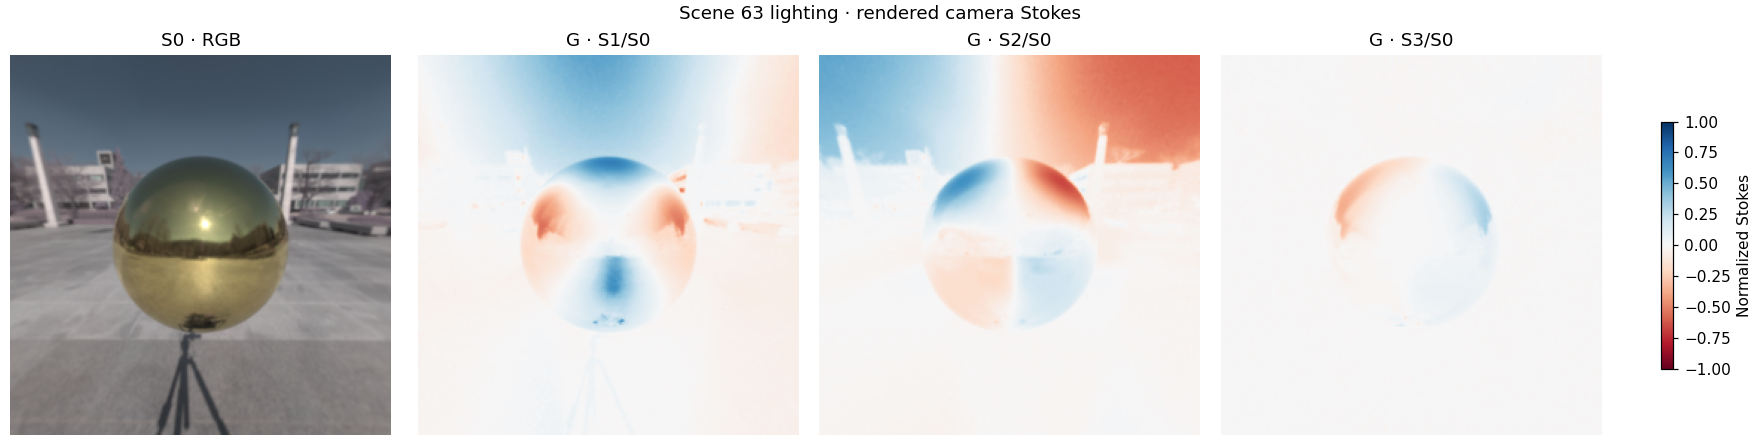

In [4]:
import matplotlib.pyplot as plt
from example.visualize import plot_stokes
figure = plot_stokes(rendered, channel=CHANNEL, limit=DISPLAY_LIMIT,
                      title="Scene 63 lighting · rendered camera Stokes")
display(figure)
plt.close(figure)
